In [1]:
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

df = pd.read_csv("../datasets/reddit.csv")
df.rename(columns={'clean_text': 'message', 'is_depression': 'label'}, inplace=True)
X_train, X_test, y_train, y_test = train_test_split(df["message"], df['label'], test_size=0.3)


In [2]:
# X_train, X_test, y_train, y_test = train_test_split(df["message"], df['label'], test_size=0.3)
# pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer()),
#     ('classifier', MultinomialNB())
# ])
# pipeline.fit(X_train, y_train)
# y_pred = pipeline.predict(X_test)

# classification_report_result = classification_report(y_test, y_pred)
# print(classification_report_result)

In [3]:
# from xgboost import XGBClassifier


# xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
# xgb_pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer()),
#     ('classifier', xgb_model)
# ])
# xgb_pipeline.fit(X_train, y_train)
# y_pred_xgb = xgb_pipeline.predict(X_test)

# classification_report_result = classification_report(y_test, y_pred_xgb)
# print(classification_report_result)

In [4]:
# from lightgbm import LGBMClassifier
# lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
# lgbm_pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer()),
#     ('classifier', lgbm_model)
# ])
# lgbm_pipeline.fit(X_train, y_train)
# y_pred_lgbm = lgbm_pipeline.predict(X_test)
# classification_report_result = classification_report(y_test, y_pred_lgbm)
# print(classification_report_result)

In [5]:
df.shape

(7731, 2)

In [6]:
df.groupby(df["label"]).count()

,message
label,
0,3900
1,3831


In [7]:
df_only_depression = df[df["label"] == 1].copy()
df_only_depression = df_only_depression.rename(columns={'message': 'sentence', 'label': 'emotion'})
df_only_depression["emotion"] = "depression"
df_only_depression

,sentence,emotion
0,we understand that most people who reply immed...,depression
1,welcome to r depression s check in post a plac...,depression
2,anyone else instead of sleeping more when depr...,depression
3,i ve kind of stuffed around a lot in my life d...,depression
4,sleep is my greatest and most comforting escap...,depression
...,...,...
3826,thlolo march eh it s because i don t want stre...,depression
3827,i hate it when i m having depression day and t...,depression
3828,educational depression,depression
3829,dmt powder helping with depression amp anxiety...,depression


<Axes: title={'center': 'Top 10 Emotions in Combined Data'}, xlabel='emotion'>

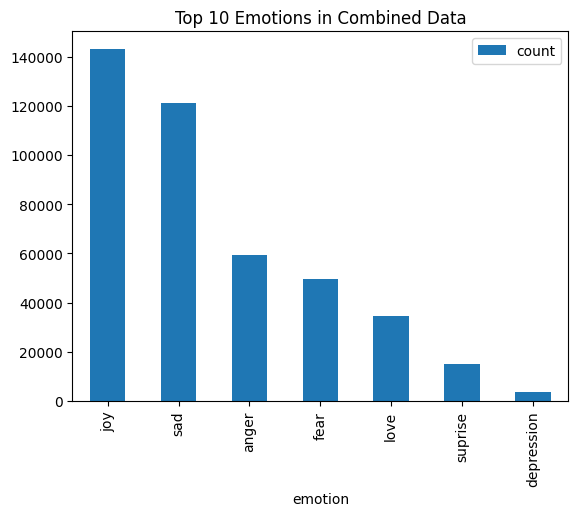

In [8]:
combined_emotion = pd.read_csv("combined_emotion.csv")
merged_df = pd.concat([combined_emotion, df_only_depression], ignore_index = True)
merged_df.groupby('emotion').size().reset_index(name='count').sort_values(by='count', ascending=False).head(10).plot(kind='bar', x='emotion', y='count', title='Top 10 Emotions in Combined Data')

In [9]:
# X_train, X_test, y_train, y_test = train_test_split(merged_df["sentence"], merged_df['emotion'], test_size=0.3)

# from lightgbm import LGBMClassifier
# lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
# lgbm_pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer()),
#     ('classifier', lgbm_model)
# ])
# lgbm_pipeline.fit(X_train, y_train)
# y_pred_lgbm = lgbm_pipeline.predict(X_test)
# classification_report_result = classification_report(y_test, y_pred_lgbm)
# print(classification_report_result)

In [10]:
# lgbm_pipeline.predict(["i missed my young brother so much", "i am so happy today because i got a new job"])

In [11]:
# merged_df.groupby('emotion').count()
# merged_df.shape
# X_train.shape

In [12]:
# from sklearn.metrics import confusion_matrix
# import seaborn as sns

# import matplotlib.pyplot as plt

# # Compute confusion matrix
# cm = confusion_matrix(y_test, y_pred_lgbm, labels=sorted(y_test.unique()))

# # Plot confusion matrix as a heatmap
# plt.figure(figsize=(10, 8))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#             xticklabels=sorted(y_test.unique()),
#             yticklabels=sorted(y_test.unique()))
# plt.xlabel('Tahmin Edilen')
# plt.ylabel('Gerçek')
# plt.title('Confusion Matrix')
# plt.savefig("confusion_matrix.png", bbox_inches='tight')
# plt.show()

In [13]:
# X_train, X_test, y_train, y_test = train_test_split(merged_df["sentence"], merged_df['emotion'], test_size=0.3)

# from lightgbm import LGBMClassifier
# lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
# lgbm_pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer(
#         max_features=10000,  # Limit the number of features to 10,000
#         ngram_range=(2, 3),  # Use unigrams and bigrams
#         stop_words='english'  # Remove English stop words
#     )),
#     ('classifier', lgbm_model)
# ])
# lgbm_pipeline.fit(X_train, y_train)
# y_pred_lgbm = lgbm_pipeline.predict(X_test)
# classification_report_result = classification_report(y_test, y_pred_lgbm)
# print(classification_report_result)

In [14]:
from lightgbm import LGBMClassifier
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

df = merged_df.copy()
df.rename(columns={'sentence': 'message', 'emotion': 'label'}, inplace=True)
X_train, X_test, y_train, y_test = train_test_split(df['message'], df['label'], test_size=0.3, random_state=42)
lgbm_model = LGBMClassifier(n_jobs=-1, reg_lambda=0.1, num_leaves=64, max_depth=-1, learning_rate=0.1, n_estimators=100)
lgbm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000, 
        ngram_range=( 1,3), 
        stop_words='english', 
        lowercase=True, 
        norm='l2', 
        use_idf=True, 
        smooth_idf=True, 
        sublinear_tf=True
    )),
    ('classifier', lgbm_model)
])
lgbm_pipeline.fit(X_train, y_train)
y_pred_lgbm = lgbm_pipeline.predict(X_test)
classification_report_result = classification_report(y_test, y_pred_lgbm)
print(classification_report_result)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 2.583564 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 439215
[LightGBM] [Info] Number of data points in the train set: 298603, number of used features: 9996
[LightGBM] [Info] Start training from score -1.974844
[LightGBM] [Info] Start training from score -4.698483
[LightGBM] [Info] Start training from score -2.149296
[LightGBM] [Info] Start training from score -1.093735
[LightGBM] [Info] Start training from score -2.508392
[LightGBM] [Info] Start training from score -1.257511
[LightGBM] [Info] Start training from score -3.357598


/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

       anger       0.91      0.94      0.92     17876
  depression       0.97      0.91      0.94      1111
        fear       0.85      0.88      0.87     14842
         joy       0.94      0.92      0.93     43046
        love       0.78      0.86      0.82     10248
         sad       0.96      0.94      0.95     36276
     suprise       0.72      0.72      0.72      4575

    accuracy                           0.91    127974
   macro avg       0.88      0.88      0.88    127974
weighted avg       0.91      0.91      0.91    127974



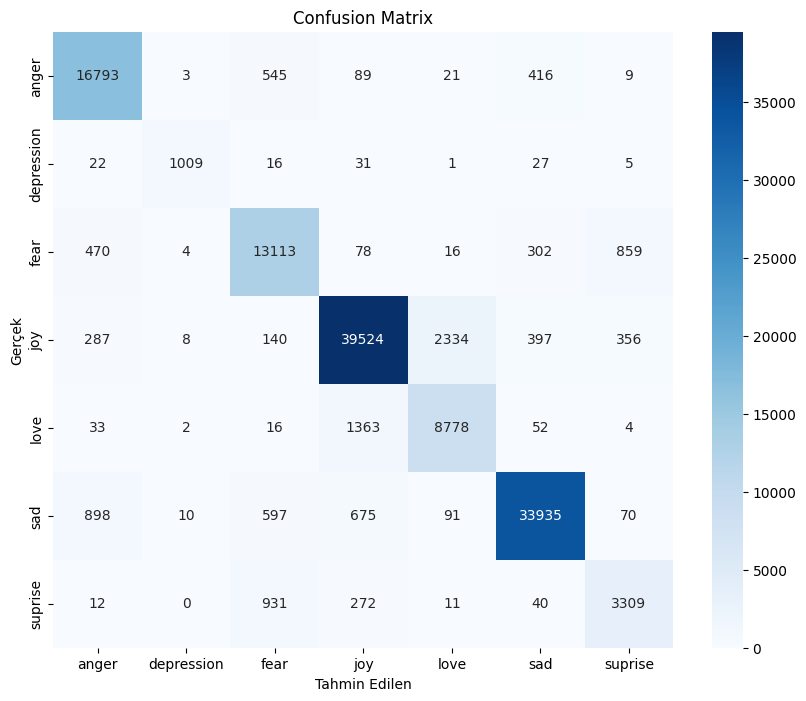

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lgbm, labels=sorted(y_test.unique()))

# Plot confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_test.unique()),
            yticklabels=sorted(y_test.unique()))
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek')
plt.title('Confusion Matrix')
plt.savefig("confusion_matrix.png", bbox_inches='tight')
plt.show()

In [16]:
lgbm_pipeline.predict(["i'm gonna kill you and make u suffered from my joy"])

/home/hyo/Documents/projects/trackerv2/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


array(['depression'], dtype=object)

,message,label
0,i just feel really helpless and heavy hearted,fear
1,ive enjoyed being able to slouch about relax a...,sad
2,i gave up my internship with the dmrg and am f...,fear
3,i dont know i feel so lost,sad
4,i am a kindergarten teacher and i am thoroughl...,fear
...,...,...
426572,thlolo march eh it s because i don t want stre...,depression
426573,i hate it when i m having depression day and t...,depression
426574,educational depression,depression
426575,dmt powder helping with depression amp anxiety...,depression


In [17]:
import matplotlib.pyplot as plt

# Bar chart for df (grouped by 'label')
plt.figure(figsize=(8, 5))
df_emotion_counts.plot.bar()
plt.title('Duygu Dağılım Grafiği')
plt.xlabel('DUYGU')
plt.ylabel('SAYI')
plt.show()

# Bar chart for y_train
plt.figure(figsize=(8, 5))
y_train_counts.plot.bar()
plt.title('Eğitim Verileri Duygu Dağılım Grafiği')
plt.xlabel('DUYGU')
plt.ylabel('SAYI')
plt.show()

# Bar chart for y_test
plt.figure(figsize=(8, 5))
y_test_counts.plot.bar()
plt.title('Test Verileri Duygu Dağılım Grafiği')
plt.xlabel('DUYGU')
plt.ylabel('SAYI')
plt.show()

NameError: name 'df_emotion_counts' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
display(df.groupby("label").count())

,message
label,
anger,59317
depression,3831
fear,49649
joy,143067
love,34554
sad,121187
suprise,14972


In [ ]:
y_train.shape[0] * 0.7

209022.09999999998

In [23]:
df["label"].unique()

array(['fear', 'sad', 'love', 'joy', 'suprise', 'anger', 'depression'],
      dtype=object)